<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №6
## по курсу «Технологии машинного обучения»

### Тема: Ансамбли моделей машинного обучения. Часть 2

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

---


## 1. Описание задания

**Цель работы:** изучение ансамблей моделей машинного обучения.

**Задание:**
1. Выбрать набор данных для решения задачи классификации или регрессии.
2. В случае необходимости провести удаление или заполнение пропусков и кодирование категориальных признаков.
3. С использованием метода train_test_split разделить выборку на обучающую и тестовую.
4. Обучить ансамблевые модели: одну из моделей группы стекинга и модель многослойного персептрона.
5. Оценить качество моделей с помощью одной из подходящих для задачи метрик. Сравнить качество полученных моделей.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import warnings

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", category=RuntimeWarning)  # лишние предупреждения numpy на macOS
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # при подборе часть сетей не успевает сойтись за 2000 эпох

BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"

## 2. Набор данных

Используется тот же финансовый датасет, что и в ЛР2–ЛР5, — **Loan Prediction Problem Dataset** (заявки на кредит, https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset). Решается задача **бинарной классификации**: предсказать `Loan_Status` — одобрят ли кредит (1) или откажут (0).

In [2]:
df = pd.read_csv("loan_prediction.csv")
print("Размер:", df.shape)
print(df["Loan_Status"].value_counts())
df.head()


Размер: (614, 13)
Loan_Status
Y    422
N    192
Name: count, dtype: int64


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 3. Предобработка данных

Пропуски заполняем медианой и модой, категориальные признаки кодируем (так же, как в ЛР2–ЛР5).

In [3]:
data = df.drop(columns=["Loan_ID"])

data[["LoanAmount"]] = SimpleImputer(strategy="median").fit_transform(data[["LoanAmount"]])
mode_cols = ["Gender", "Married", "Dependents", "Self_Employed", "Loan_Amount_Term", "Credit_History"]
data[mode_cols] = SimpleImputer(strategy="most_frequent").fit_transform(data[mode_cols])

for col in ["Gender", "Married", "Education", "Self_Employed", "Loan_Status"]:
    data[col] = LabelEncoder().fit_transform(data[col])
data["Dependents"] = OrdinalEncoder(categories=[["0", "1", "2", "3+"]]).fit_transform(data[["Dependents"]])
data = pd.get_dummies(data, columns=["Property_Area"], prefix="Area", dtype=int)
data = data.astype(float)

print("Пропусков:", data.isnull().sum().sum())
data.head()


Пропусков: 0


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Area_Rural,Area_Semiurban,Area_Urban
0,1.0,0.0,0.0,0.0,0.0,5849.0,0.0,128.0,360.0,1.0,1.0,0.0,0.0,1.0
1,1.0,1.0,1.0,0.0,0.0,4583.0,1508.0,128.0,360.0,1.0,0.0,1.0,0.0,0.0
2,1.0,1.0,0.0,0.0,1.0,3000.0,0.0,66.0,360.0,1.0,1.0,0.0,0.0,1.0
3,1.0,1.0,0.0,1.0,0.0,2583.0,2358.0,120.0,360.0,1.0,1.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,6000.0,0.0,141.0,360.0,1.0,1.0,0.0,0.0,1.0


## 4. Разделение на обучающую и тестовую выборки

Нейронная сеть, логистическая регрессия и метод ближайших соседей чувствительны к масштабу признаков, поэтому после разделения признаки масштабируем (StandardScaler обучаем только на обучающей выборке).

In [4]:
X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)
print("Обучающая выборка:", X_train.shape, " Тестовая выборка:", X_test.shape)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Обучающая выборка: (460, 13)  Тестовая выборка: (154, 13)


## 5. Обучение моделей

Основная метрика — **F1-мера** (классы несбалансированы: одобренных заявок примерно в 2 раза больше). Дополнительно выводим accuracy и ROC-AUC.

In [5]:
results = {}
scores = {}  # вероятности для ROC-кривых

def evaluate(name, model, X_tr, X_te):
    pred = model.predict(X_te)
    score = model.predict_proba(X_te)[:, 1]
    scores[name] = score
    results[name] = {
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    print(name)
    print("  Accuracy на обучающей:", round(accuracy_score(y_train, model.predict(X_tr)), 4))
    for k, v in results[name].items():
        print(f"  {k:9} {v:.4f}")
    return pred

### 5.1. Стекинг

Стекинг объединяет **разные** модели. Базовые модели делают предсказания, а мета-модель (логистическая регрессия) учится, как лучше объединить их ответы. Чтобы мета-модель не училась на «подсмотренных» ответах, предсказания базовых моделей для неё получаются кросс-валидацией (cv=5).

Базовые модели — из прошлых лабораторных: случайный лес и AdaBoost (ЛР5), метод ближайших соседей с K=16 (ЛР3), логистическая регрессия (ЛР4).

In [6]:
base_models = [
    ("forest", RandomForestClassifier(n_estimators=100, max_depth=4, random_state=1)),
    ("ada", AdaBoostClassifier(n_estimators=100, random_state=1)),
    ("knn", KNeighborsClassifier(n_neighbors=16)),
    ("logreg", LogisticRegression(max_iter=1000)),
]

# сначала посмотрим, как каждая базовая модель работает отдельно
for name, model in base_models:
    model.fit(X_train_sc, y_train)
    print(f"{name:7} F1 на тесте = {f1_score(y_test, model.predict(X_test_sc)):.4f}")

forest  F1 на тесте = 0.8870
ada     F1 на тесте = 0.8908
knn     F1 на тесте = 0.8724
logreg  F1 на тесте = 0.8870


In [7]:
stacking = StackingClassifier(estimators=base_models,
                              final_estimator=LogisticRegression(max_iter=1000), cv=5)
stacking.fit(X_train_sc, y_train)
pred_stack = evaluate("Стекинг", stacking, X_train_sc, X_test_sc)

Стекинг
  Accuracy на обучающей: 0.8087
  F1        0.8870
  Accuracy  0.8247
  ROC-AUC   0.7771


In [8]:
# какой вес мета-модель дала каждой базовой модели
weights = pd.Series(stacking.final_estimator_.coef_[0], index=[n for n, _ in base_models])
weights.round(3)

forest    2.014
ada       0.932
knn       0.293
logreg    2.630
dtype: float64

### 5.2. Многослойный персептрон (нейронная сеть)

Многослойный персептрон (MLPClassifier) — нейронная сеть из нескольких слоёв нейронов. Каждый нейрон берёт взвешенную сумму входов и пропускает её через функцию активации (ReLU). Веса подбираются по ошибке методом обратного распространения (оптимизатор adam).

Сначала обучим простую сеть с двумя скрытыми слоями по 16 и 8 нейронов.

In [9]:
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=2000, random_state=1)
mlp.fit(X_train_sc, y_train)
print("Число итераций обучения:", mlp.n_iter_)
pred_mlp = evaluate("Персептрон (16, 8)", mlp, X_train_sc, X_test_sc)

Число итераций обучения: 1795
Персептрон (16, 8)
  Accuracy на обучающей: 0.9435
  F1        0.8318
  Accuracy  0.7662
  ROC-AUC   0.7624


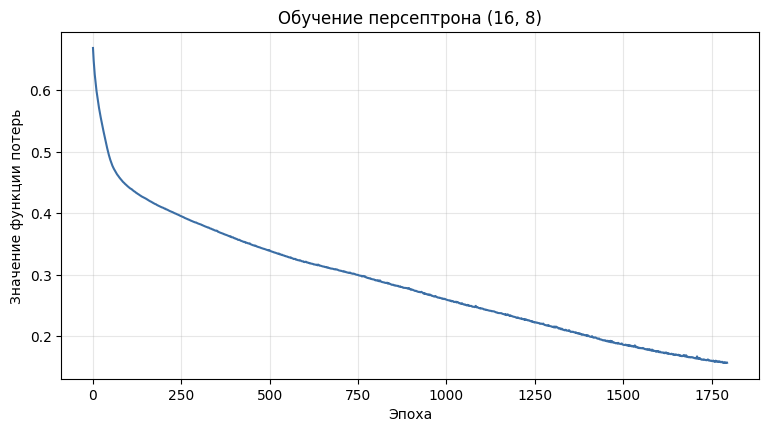

In [10]:
# кривая обучения: как уменьшалась ошибка (функция потерь) по эпохам
plt.figure(figsize=(9, 4.5))
plt.plot(mlp.loss_curve_, color=BLUE)
plt.xlabel("Эпоха")
plt.ylabel("Значение функции потерь")
plt.title("Обучение персептрона (16, 8)")
plt.grid(alpha=0.3)
plt.show()

In [11]:
# подберём размер сети и силу регуляризации alpha кросс-валидацией на обучающей выборке
cv_f1 = {}
for layers in [(8,), (16,), (16, 8), (32, 16)]:
    for alpha in [0.0001, 0.01, 1.0]:
        m = MLPClassifier(hidden_layer_sizes=layers, alpha=alpha, max_iter=2000, random_state=1)
        cv_f1[(layers, alpha)] = cross_val_score(m, X_train_sc, y_train, cv=5, scoring="f1").mean()
        print(f"слои={str(layers):9} alpha={alpha:<7} F1 на кросс-валидации = {cv_f1[(layers, alpha)]:.4f}")

best_layers, best_alpha = max(cv_f1, key=cv_f1.get)
print("Лучшие параметры:", best_layers, best_alpha)

слои=(8,)      alpha=0.0001  F1 на кросс-валидации = 0.8590


слои=(8,)      alpha=0.01    F1 на кросс-валидации = 0.8590


слои=(8,)      alpha=1.0     F1 на кросс-валидации = 0.8634


слои=(16,)     alpha=0.0001  F1 на кросс-валидации = 0.8134


слои=(16,)     alpha=0.01    F1 на кросс-валидации = 0.8135


...

слои=(16, 8)   alpha=0.01    F1 на кросс-валидации = 0.8017


слои=(16, 8)   alpha=1.0     F1 на кросс-валидации = 0.8172


слои=(32, 16)  alpha=0.0001  F1 на кросс-валидации = 0.8000


слои=(32, 16)  alpha=0.01    F1 на кросс-валидации = 0.8134


слои=(32, 16)  alpha=1.0     F1 на кросс-валидации = 0.8102
Лучшие параметры: (8,) 1.0


In [12]:
mlp_best = MLPClassifier(hidden_layer_sizes=best_layers, alpha=best_alpha, max_iter=2000, random_state=1)
mlp_best.fit(X_train_sc, y_train)
pred_mlp_best = evaluate(f"Персептрон {best_layers}, alpha={best_alpha}", mlp_best, X_train_sc, X_test_sc)

Персептрон (8,), alpha=1.0
  Accuracy на обучающей: 0.8239
  F1        0.8908
  Accuracy  0.8312
  ROC-AUC   0.7643


## 6. Сравнение качества моделей

Для сравнения добавим лучшую модель из ЛР5 — AdaBoost.

In [13]:
ada = AdaBoostClassifier(n_estimators=100, random_state=1).fit(X_train_sc, y_train)
pred_ada = evaluate("AdaBoost (из ЛР5)", ada, X_train_sc, X_test_sc)

compare = pd.DataFrame(results).T.round(4).sort_values("F1", ascending=False)
compare

AdaBoost (из ЛР5)
  Accuracy на обучающей: 0.8152
  F1        0.8908
  Accuracy  0.8312
  ROC-AUC   0.7501


,F1,Accuracy,ROC-AUC
"Персептрон (8,), alpha=1.0",0.8908,0.8312,0.7643
AdaBoost (из ЛР5),0.8908,0.8312,0.7501
Стекинг,0.8870,0.8247,0.7771
"Персептрон (16, 8)",0.8318,0.7662,0.7624


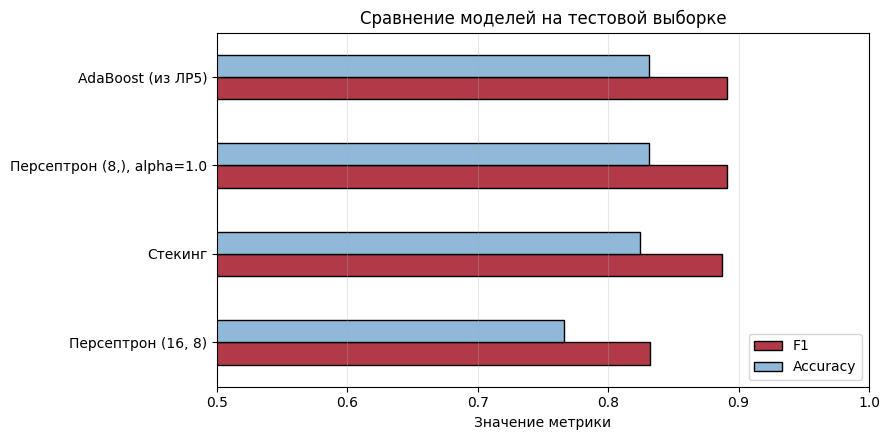

In [14]:
ax = compare[["F1", "Accuracy"]].sort_values("F1").plot(kind="barh", figsize=(9, 4.5),
                                                    color=[RED, BLUE_LIGHT], edgecolor="black")
plt.title("Сравнение моделей на тестовой выборке")
plt.xlabel("Значение метрики")
plt.xlim(0.5, 1)
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

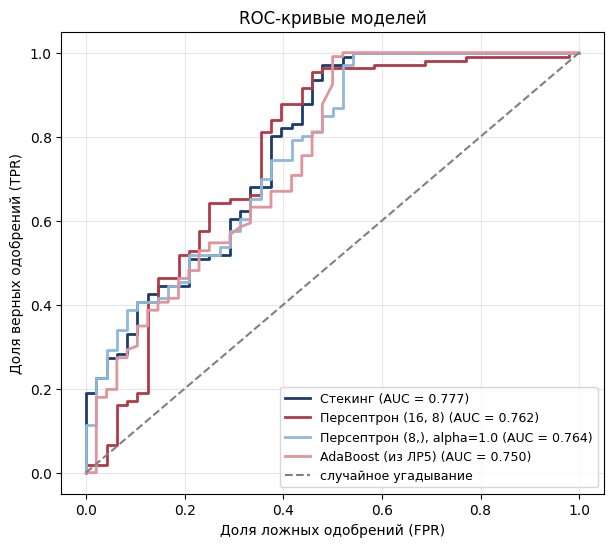

In [15]:
# ROC-кривые: чем ближе кривая к левому верхнему углу, тем лучше модель разделяет классы
plt.figure(figsize=(7, 6))
for (name, score), color in zip(scores.items(), [BLUE_DARK, RED, BLUE_LIGHT, RED_LIGHT]):
    fpr, tpr, _ = roc_curve(y_test, score)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="случайное угадывание")
plt.xlabel("Доля ложных одобрений (FPR)")
plt.ylabel("Доля верных одобрений (TPR)")
plt.title("ROC-кривые моделей")
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.show()

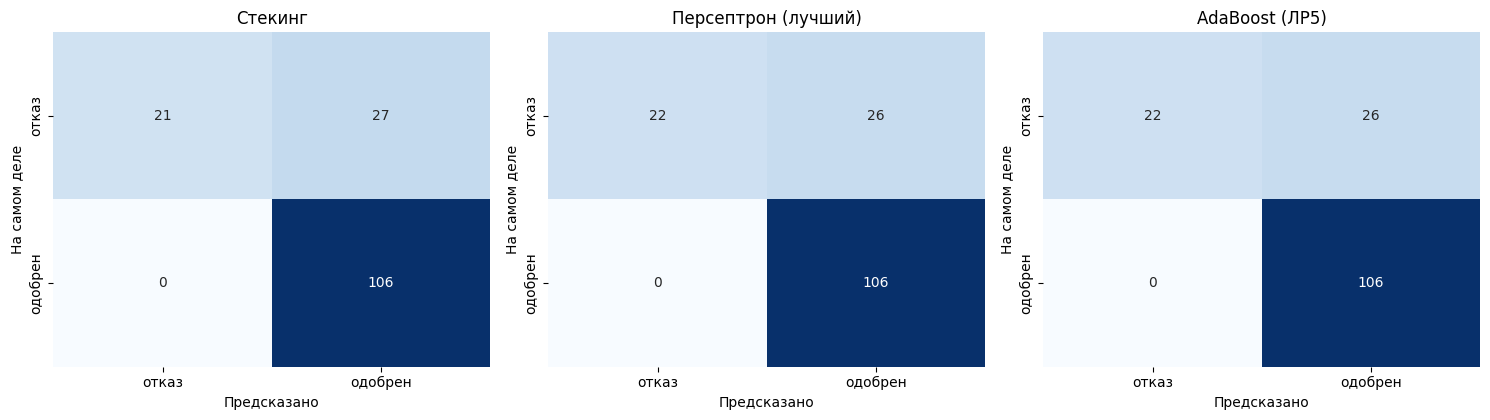

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (title, pred) in zip(axes, [("Стекинг", pred_stack), ("Персептрон (лучший)", pred_mlp_best),
                                     ("AdaBoost (ЛР5)", pred_ada)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["отказ", "одобрен"], yticklabels=["отказ", "одобрен"])
    ax.set_title(title)
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("На самом деле")
plt.tight_layout()
plt.show()

## 7. Выводы

1. Для задачи бинарной классификации (одобрение кредита) использован датасет Loan Prediction: пропуски заполнены, категориальные признаки закодированы, выборка разделена на обучающую и тестовую (75/25, со стратификацией), признаки масштабированы.
2. Обучен стекинг из четырёх разных базовых моделей (случайный лес, AdaBoost, метод ближайших соседей, логистическая регрессия) с мета-моделью — логистической регрессией. Стекинг получил F1 0,887 и лучший среди всех моделей ROC-AUC — 0,777. Больший вес мета-модель дала логистической регрессии и случайному лесу.
3. Многослойный персептрон с двумя скрытыми слоями (16, 8) переобучился: accuracy 0,944 на обучающей и 0,766 на тестовой выборке, F1 0,832. Подбор размера сети и регуляризации alpha кросс-валидацией показал, что для небольшого датасета лучше маленькая сеть с сильной регуляризацией: один слой из 8 нейронов и alpha = 1.
4. Подобранный персептрон показал F1 0,891 и accuracy 0,831 — столько же, сколько лучшая модель ЛР5 (AdaBoost), а по ROC-AUC он лучше AdaBoost (0,764 против 0,750).
5. Все лучшие модели (стекинг, персептрон, AdaBoost) дают почти одинаковое качество: на этом датасете (614 заявок) основную информацию несёт один признак — кредитная история, поэтому усложнение модели почти не повышает качество. Дополнительная часть с МГУА не выполнялась: библиотека gmdh пока не решает задачу классификации.